# 02 — Exploratory Analysis

This notebook examines how order position, queue state, and current
limit-order-book conditions relate to fixed-horizon fill outcomes.

All exploratory relationships are calculated using the training set only.
Each horizon uses only observations eligible for that horizon.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

excel_files = list(RAW_DIR.glob("*.xlsx"))

assert len(excel_files) == 1

orders = pd.read_excel(
    excel_files[0],
    sheet_name="Orders"
)

train = orders.loc[
    orders["data_split"].astype(str).str.lower().eq("train")
].copy()

print("All observations:", len(orders))
print("Training observations:", len(train))

Matplotlib is building the font cache; this may take a moment.


All observations: 10000
Training observations: 7000


In [2]:
baseline_rows = []

for horizon in [5, 30, 60]:
    eligibility_column = f"eligible_{horizon}s"
    target_column = f"target_fill_{horizon}s"

    eligible = train.loc[
        train[eligibility_column].eq(1),
        target_column
    ]

    baseline_rows.append({
        "horizon_seconds": horizon,
        "eligible_orders": len(eligible),
        "fill_rate_pct": 100 * eligible.mean()
    })

training_baselines = pd.DataFrame(baseline_rows)
training_baselines.round(2)

,horizon_seconds,eligible_orders,fill_rate_pct
0,5,6807,10.45
1,30,6173,41.81
2,60,5777,63.30


In [3]:
eda_30s = train.loc[
    train["eligible_30s"].eq(1)
].copy()

price_distance_table = (
    eda_30s
    .groupby("price_distance_ticks")
    .agg(
        eligible_orders=("target_fill_30s", "size"),
        fill_rate=("target_fill_30s", "mean")
    )
    .reset_index()
)

price_distance_table["fill_rate_pct"] = (
    100 * price_distance_table["fill_rate"]
)

price_distance_table.round(2)

,price_distance_ticks,eligible_orders,fill_rate,fill_rate_pct
0,0,5050,0.46,45.94
1,1,598,0.31,31.27
2,2,281,0.18,17.79
3,3,181,0.13,12.71
4,4,63,0.02,1.59


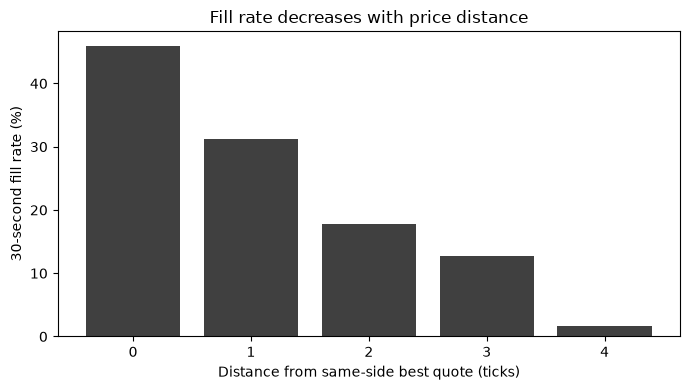

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(
    price_distance_table["price_distance_ticks"],
    price_distance_table["fill_rate_pct"],
    color="0.25"
)

ax.set_xlabel("Distance from same-side best quote (ticks)")
ax.set_ylabel("30-second fill rate (%)")
ax.set_title("Fill rate decreases with price distance")
ax.set_xticks(price_distance_table["price_distance_ticks"])

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "fill_rate_by_price_distance_30s.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [5]:
eda_30s["queue_position_group"] = pd.qcut(
    eda_30s["normalized_queue_ahead"],
    q=4,
    labels=[
        "Q1: closest to front",
        "Q2",
        "Q3",
        "Q4: furthest back"
    ]
)

queue_table = (
    eda_30s
    .groupby("queue_position_group", observed=True)
    .agg(
        eligible_orders=("target_fill_30s", "size"),
        mean_queue_ahead=("normalized_queue_ahead", "mean"),
        fill_rate=("target_fill_30s", "mean")
    )
    .reset_index()
)

queue_table["fill_rate_pct"] = 100 * queue_table["fill_rate"]

queue_table.round(3)

,queue_position_group,eligible_orders,mean_queue_ahead,fill_rate,fill_rate_pct
0,Q1: closest to front,1544,0.346,0.505,50.453
1,Q2,1543,0.651,0.405,40.506
2,Q3,1543,0.758,0.394,39.404
3,Q4: furthest back,1543,0.899,0.369,36.876


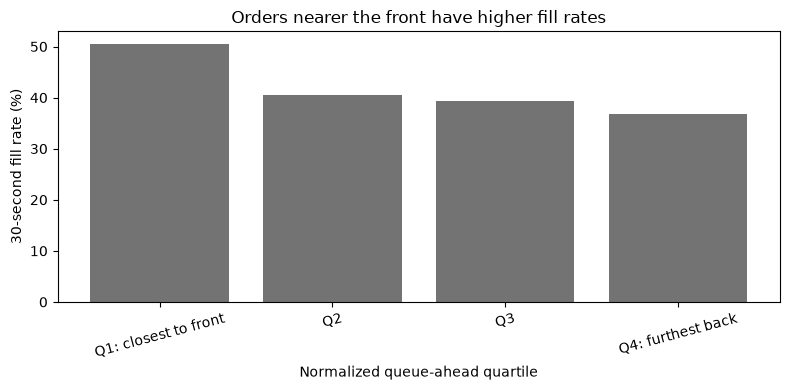

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(
    queue_table["queue_position_group"].astype(str),
    queue_table["fill_rate_pct"],
    color="0.45"
)

ax.set_xlabel("Normalized queue-ahead quartile")
ax.set_ylabel("30-second fill rate (%)")
ax.set_title("Orders nearer the front have higher fill rates")
ax.tick_params(axis="x", rotation=15)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "fill_rate_by_queue_position_30s.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [7]:
eda_30s["oriented_top_imbalance"] = np.where(
    eda_30s["side"].astype(str).str.lower().eq("buy"),
    eda_30s["top_level_imbalance"],
    -eda_30s["top_level_imbalance"]
)

eda_30s["imbalance_group"] = pd.qcut(
    eda_30s["oriented_top_imbalance"],
    q=4,
    labels=[
        "Q1: opposite side heavier",
        "Q2",
        "Q3",
        "Q4: same side heavier"
    ]
)

imbalance_table = (
    eda_30s
    .groupby("imbalance_group", observed=True)
    .agg(
        eligible_orders=("target_fill_30s", "size"),
        mean_oriented_imbalance=(
            "oriented_top_imbalance",
            "mean"
        ),
        fill_rate=("target_fill_30s", "mean")
    )
    .reset_index()
)

imbalance_table["fill_rate_pct"] = (
    100 * imbalance_table["fill_rate"]
)

imbalance_table.round(3)

,imbalance_group,eligible_orders,mean_oriented_imbalance,fill_rate,fill_rate_pct
0,Q1: opposite side heavier,1544,-0.716,0.506,50.583
1,Q2,1563,-0.196,0.401,40.115
2,Q3,1523,0.202,0.383,38.345
3,Q4: same side heavier,1543,0.722,0.382,38.172


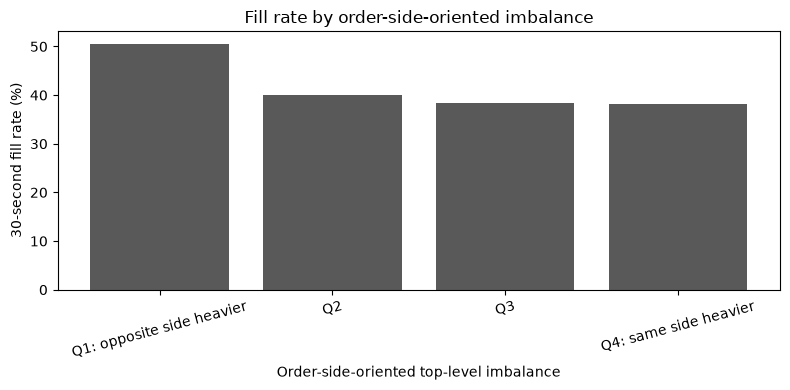

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(
    imbalance_table["imbalance_group"].astype(str),
    imbalance_table["fill_rate_pct"],
    color="0.35"
)

ax.set_xlabel("Order-side-oriented top-level imbalance")
ax.set_ylabel("30-second fill rate (%)")
ax.set_title("Fill rate by order-side-oriented imbalance")
ax.tick_params(axis="x", rotation=15)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "fill_rate_by_oriented_imbalance_30s.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [9]:
eda_30s["aggressive_volume_group"] = pd.qcut(
    eda_30s["aggressive_trade_volume_against_order_10s"],
    q=4,
    labels=[
        "Q1: lowest",
        "Q2",
        "Q3",
        "Q4: highest"
    ]
)

aggressive_flow_table = (
    eda_30s
    .groupby("aggressive_volume_group", observed=True)
    .agg(
        eligible_orders=("target_fill_30s", "size"),
        mean_aggressive_volume=(
            "aggressive_trade_volume_against_order_10s",
            "mean"
        ),
        fill_rate=("target_fill_30s", "mean")
    )
    .reset_index()
)

aggressive_flow_table["fill_rate_pct"] = (
    100 * aggressive_flow_table["fill_rate"]
)

aggressive_flow_table.round(2)

,aggressive_volume_group,eligible_orders,mean_aggressive_volume,fill_rate,fill_rate_pct
0,Q1: lowest,1561,61.61,0.33,32.80
1,Q2,1535,177.76,0.40,40.13
2,Q3,1540,318.24,0.46,45.58
3,Q4: highest,1537,739.29,0.49,48.86


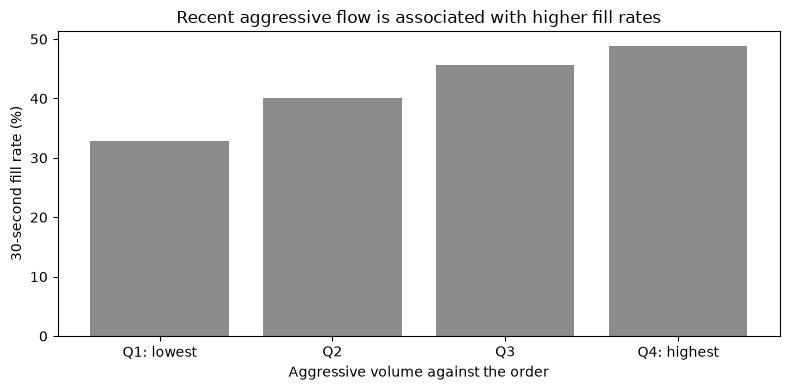

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(
    aggressive_flow_table["aggressive_volume_group"].astype(str),
    aggressive_flow_table["fill_rate_pct"],
    color="0.55"
)

ax.set_xlabel("Aggressive volume against the order")
ax.set_ylabel("30-second fill rate (%)")
ax.set_title("Recent aggressive flow is associated with higher fill rates")

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "fill_rate_by_aggressive_volume_30s.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

## Interpretation

1. Why must raw bid-ask imbalance be interpreted differently for buy
   and sell orders?
   Raw top-level imbalance is bid-ask oriented rather than order-side
oriented. A positive value means that bid depth exceeds ask depth,
but bid is the same side for a buy order and the opposite side for
a sell order. The sign must therefore be reversed for sell orders
before buy and sell observations can be interpreted together.


2. Through what queue mechanism can aggressive volume against the
   resting order increase its fill probability?
A larger normalized queue ahead means that more displayed quantity
must be consumed before the studied order can trade under price-time
priority. It is therefore associated with a lower short-horizon fill
rate.

3. Why do these grouped fill rates not establish a causal relationship?
Aggressive volume against the resting order consumes liquidity on the
order's side of the book. This can advance the order's queue position,
although the grouped results show association rather than a causal
effect.